In [1]:
from config import CONFIG
from data.load import load_all_data
from tools import (
    compute_comet_pseudotime, assign_velten_celltypes,
    plot_atom_weights, plot_pseudotime, plot_velocity_streamlines,
    plot_marker_expression, analyze_transition_zones,
    analyze_trajectory_genes, grn_sparsity_report,
    compare_to_celloracle, plot_grn_consistency,
)
import numpy as np

In [2]:
data   = load_all_data(CONFIG)
run    = f"{CONFIG['OUTPUT_DIR']}/run0"
V_pred = np.load(f"{run}/V_pred.npy")
V_dec2 = np.load(f"{run}/V_dec2.npy")
mix_w  = np.load(f"{run}/mix_weights.npy")


/home/sc5625/cll_project/decipher_atac_project/decipher-atac/comet/data/load.py:31: UserWarning: `flavor='seurat_v3'` expects raw count data, but non-integers were found.
  sc.pp.highly_variable_genes(


HVGs selected: 3000
A_genes=2820, A_tfs=277, M=(2820, 277)


In [3]:
%matplotlib inline
pt = compute_comet_pseudotime(V_pred, data["X"], V_dec2, mix_w)

[pseudotime] Projecting velocity to 2D Decipher space...
[pseudotime] Building 2D Markov transition matrix...
[pseudotime] Origin atom (argmin mean weight): 3
[pseudotime] Root cells: n=52 (top 5.0% of atom-3 weight)
[pseudotime] Running Dijkstra...
[pseudotime] Done. Range: [0.0000, 1.0000]


/home/sc5625/cll_project/decipher_atac_project/decipher-atac/comet/data/load.py:31: UserWarning: `flavor='seurat_v3'` expects raw count data, but non-integers were found.
  sc.pp.highly_variable_genes(


HVGs selected: 3000
A_genes=2820, A_tfs=277, M=(2820, 277)


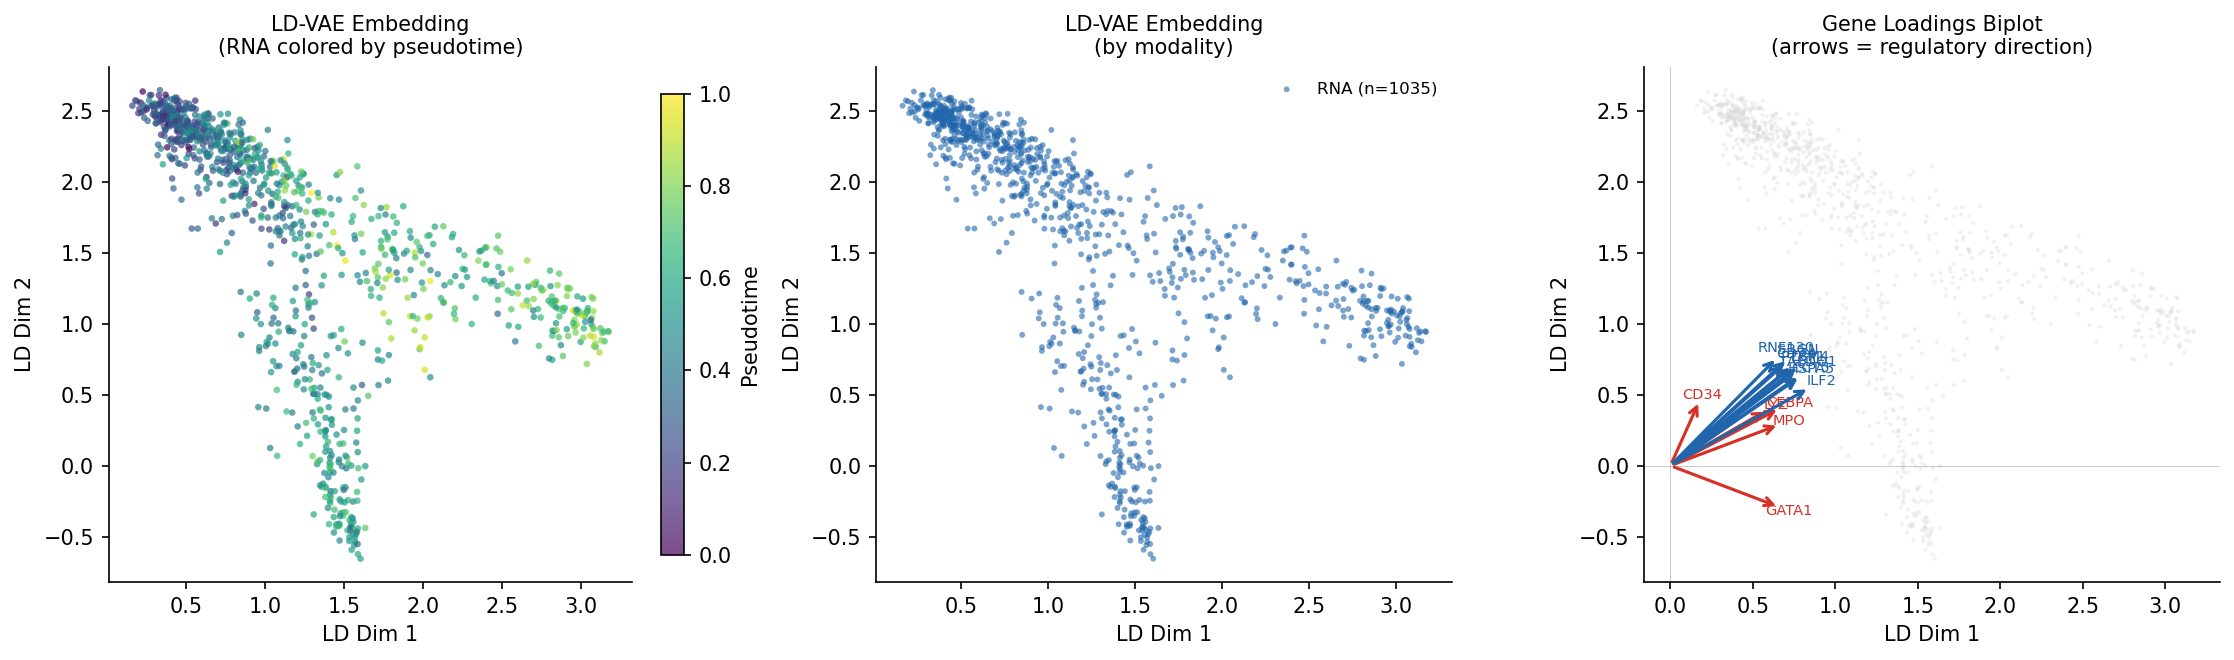

LD-VAE biplot saved: outputs/run0/plots/ld_embedding_biplot.png
Atom usage stats (atoms should NOT all be equal):
  Mean mixing weights: [0.248 0.26  0.25  0.243]
  Std  mixing weights: [0.014 0.015 0.016 0.013]
  Mean entropy: 1.384 / 1.39 max


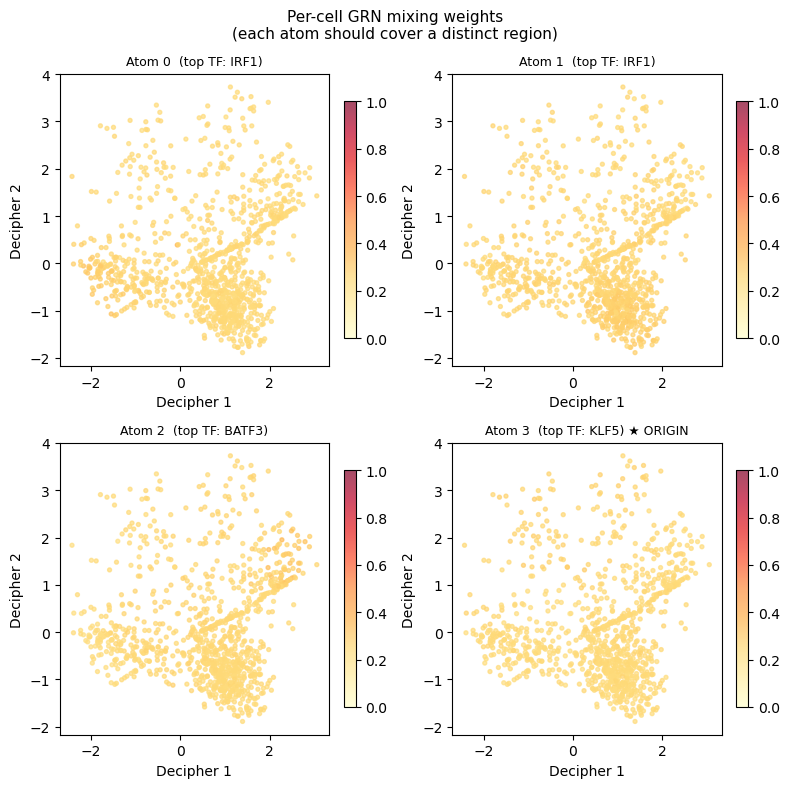

Cell type counts (FACS gates + marker rescue):
  CLOUD   : 296
  MEP     : 208
  GMP     : 157
  MPP     : 149
  HSC     : 93
  MLP     : 80
  CMP     : 52


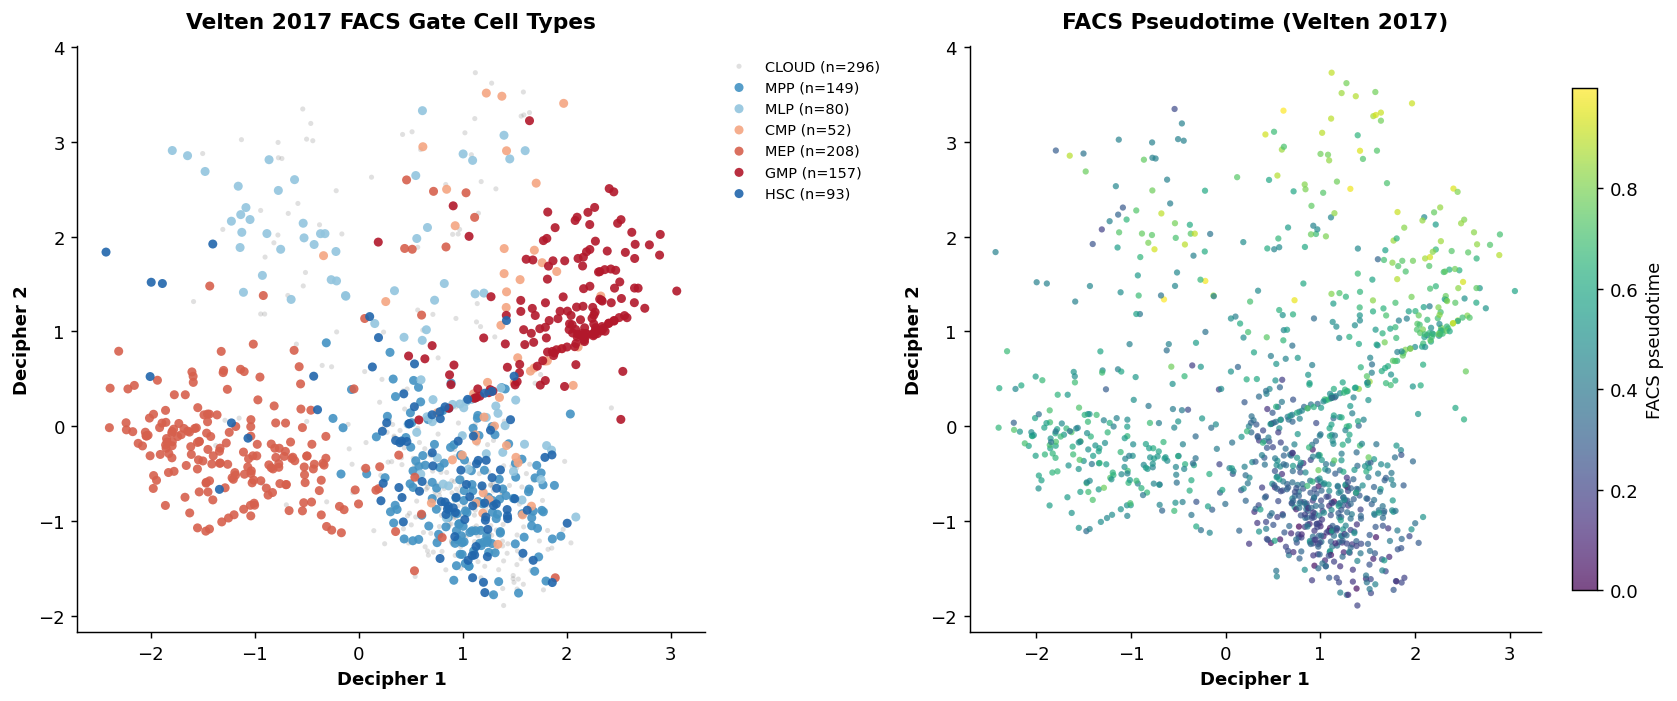

[pseudotime] Projecting velocity to 2D Decipher space...
[pseudotime] Building 2D Markov transition matrix...
[pseudotime] Origin atom (argmin mean weight): 3
[pseudotime] Root cells: n=52 (top 5.0% of atom-3 weight)
  Root cell types: ['CLOUD' 'CMP' 'GMP' 'HSC' 'MEP' 'MLP' 'MPP']
[pseudotime] Running Dijkstra...
[pseudotime] Done. Range: [0.0000, 1.0000]


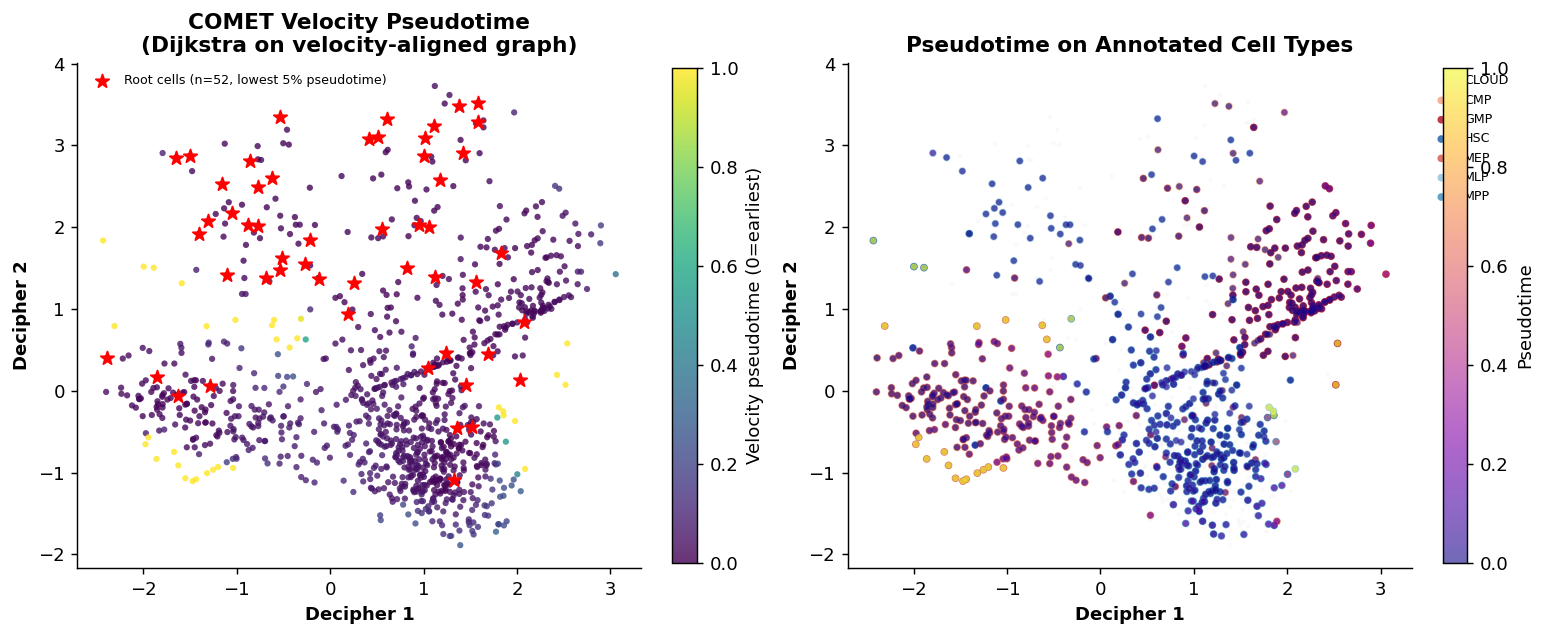


Correlation with FACS pseudotime: Spearman ρ=-0.409, p=0.0000
  ρ > 0.5 → pseudotime strongly recapitulates known ordering
  ρ > 0.3 → reasonable, especially for branching trajectories
  ρ < 0.2 → velocity field may have wrong direction or poor resolution
  ✓ Purple/dark cells should overlap HSC/MPP.
  ✓ Yellow/bright cells should overlap GMP, MEP, MLP.
Saved: outputs/run0/plots/velocity_streamlines_decipher.png


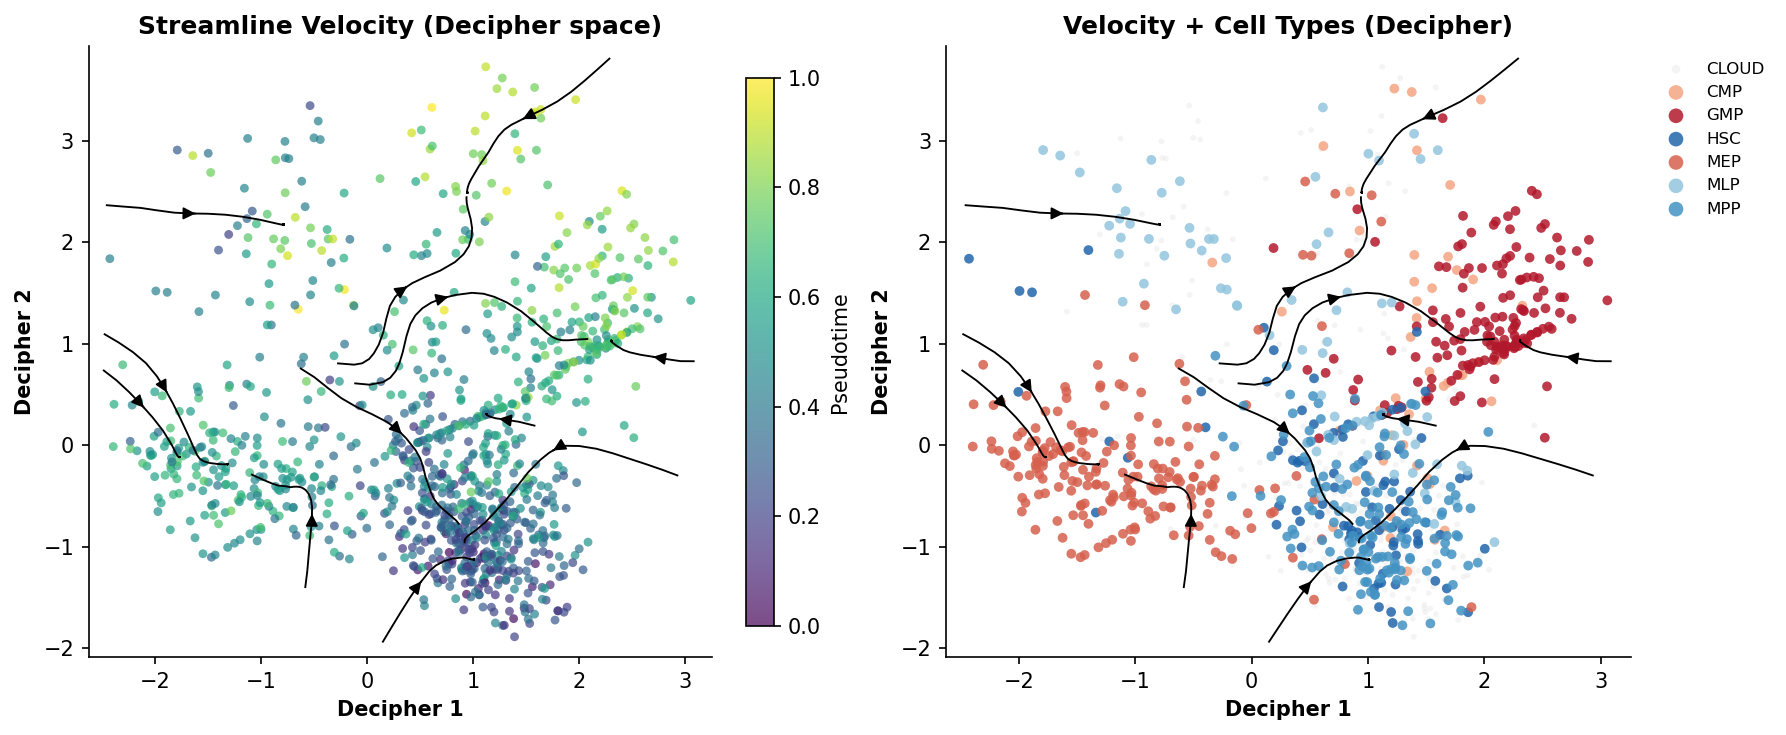

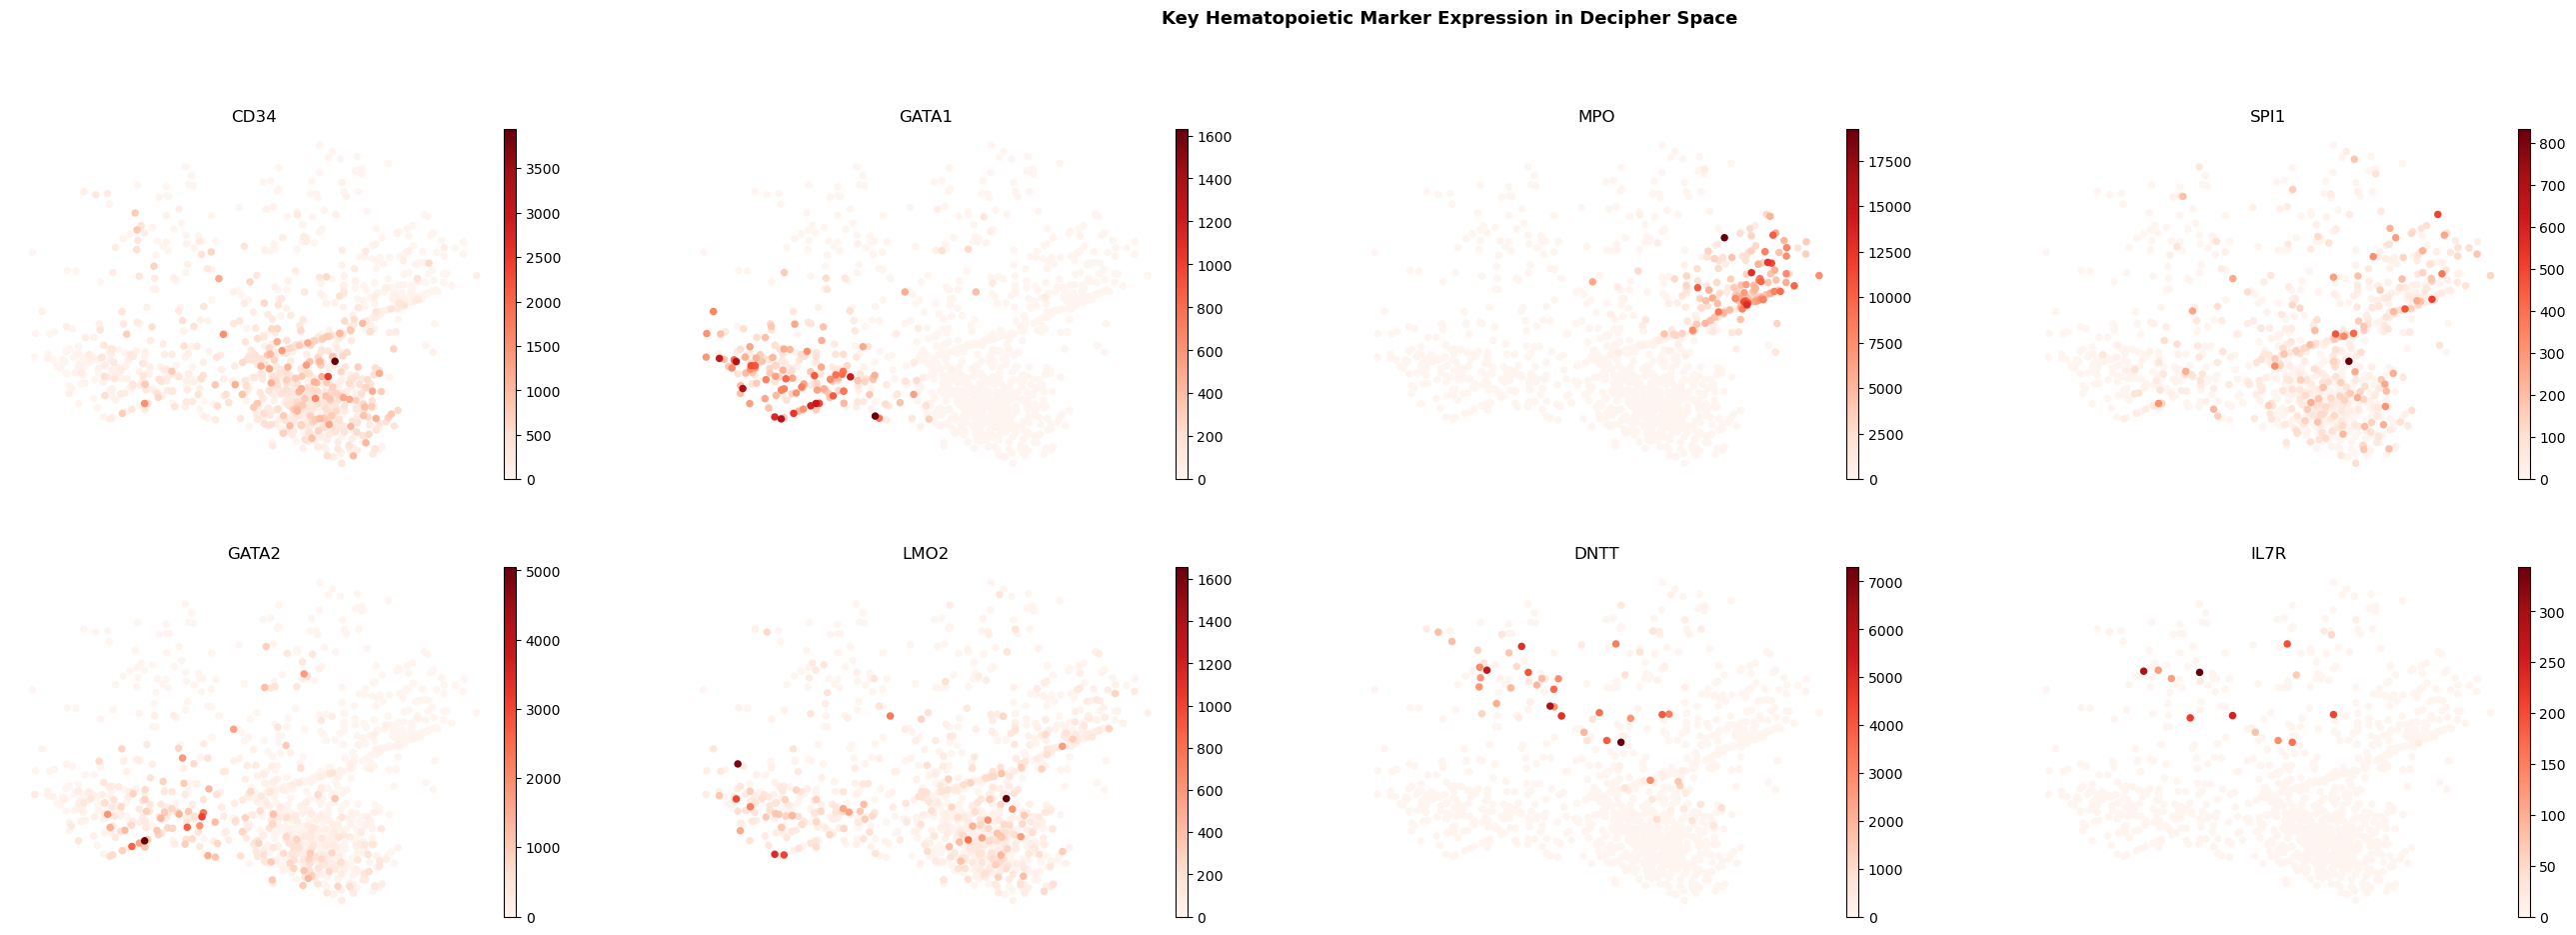

Spearman(GRN entropy, |V_smooth|): rho=0.013, p=0.6855
(Positive rho = transition cells have higher velocity — expected ✓)
(Note: with ReLU kernel, committed cells have V=0, so rho should be strongly positive)


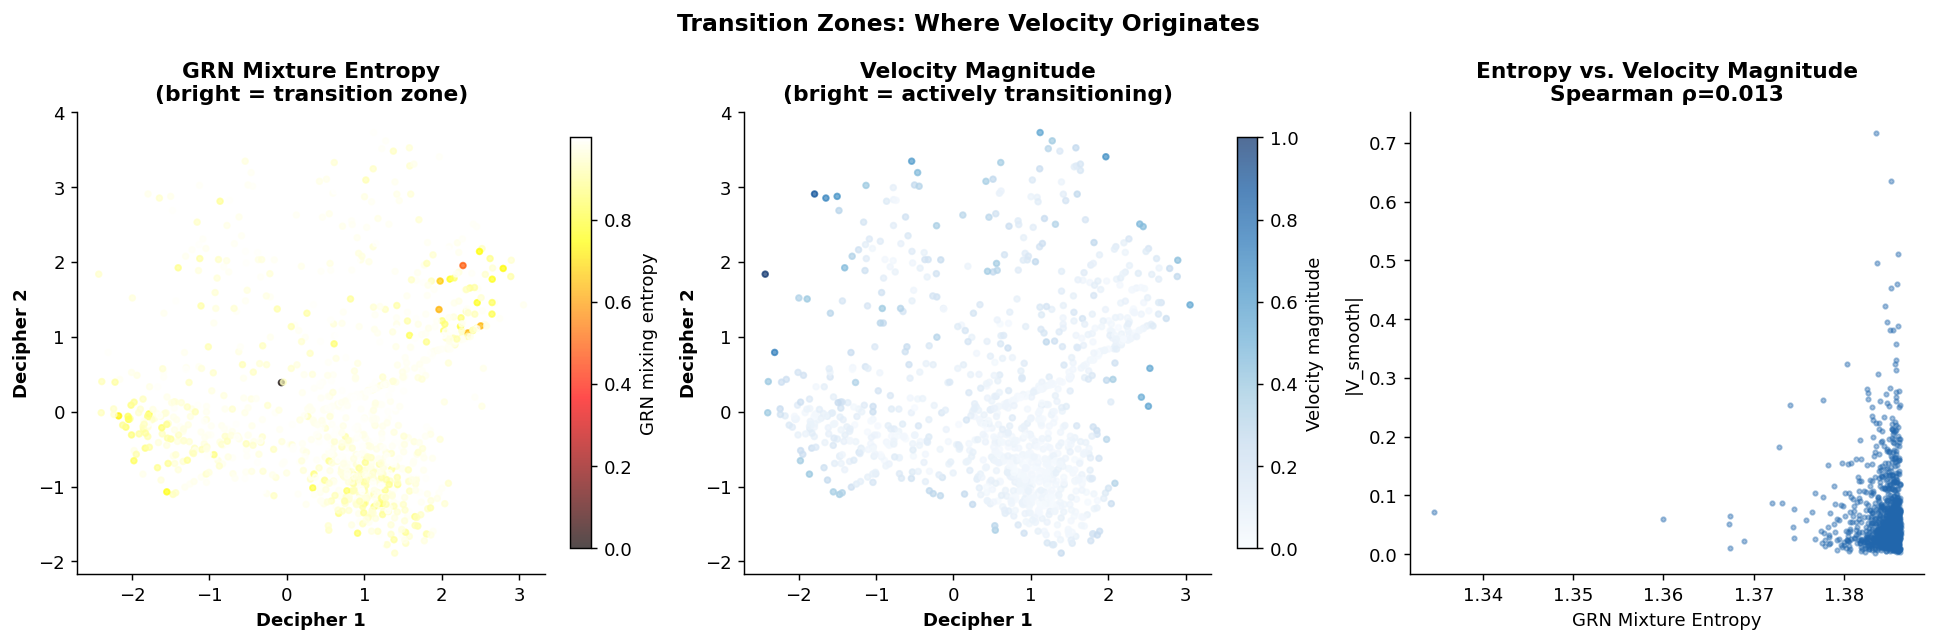

Analyzing trajectories: ['CMP', 'GMP', 'HSC', 'MEP', 'MLP', 'MPP']

HOW TO INTERPRET:
  Panel 1 (heatmap): left=early, right=late. Top rows should brighten left→right.
  Panel 2 (curves):  lineage markers should rise, stem genes fall.
  Panel 3 (spatial): top gene should be bright in the lineage region.
  Panel 4 (GT bar):  fraction of top-N genes in known Velten 2017 markers.

── CMP ─────────────────────────────────────────────
  Top genes INCREASING with pseudotime (should include lineage markers):
    MFNG             ρ=0.510  
    MEST             ρ=0.481  
    AVP              ρ=0.456  
    PRDX1            ρ=0.451  
    CD164            ρ=0.447  
    PRKG2            ρ=0.430  
    CRHBP            ρ=0.430  
    C3orf80          ρ=0.419  
    DHRS13           ρ=0.418  
    TMBIM6           ρ=0.408  
  Top genes DECREASING (stem genes leaving):
    IL2RG            ρ=-0.507  
    GPR183           ρ=-0.467  
    IGLL1            ρ=-0.429  
    H1FX             ρ=-0.426  
    PGAP3 

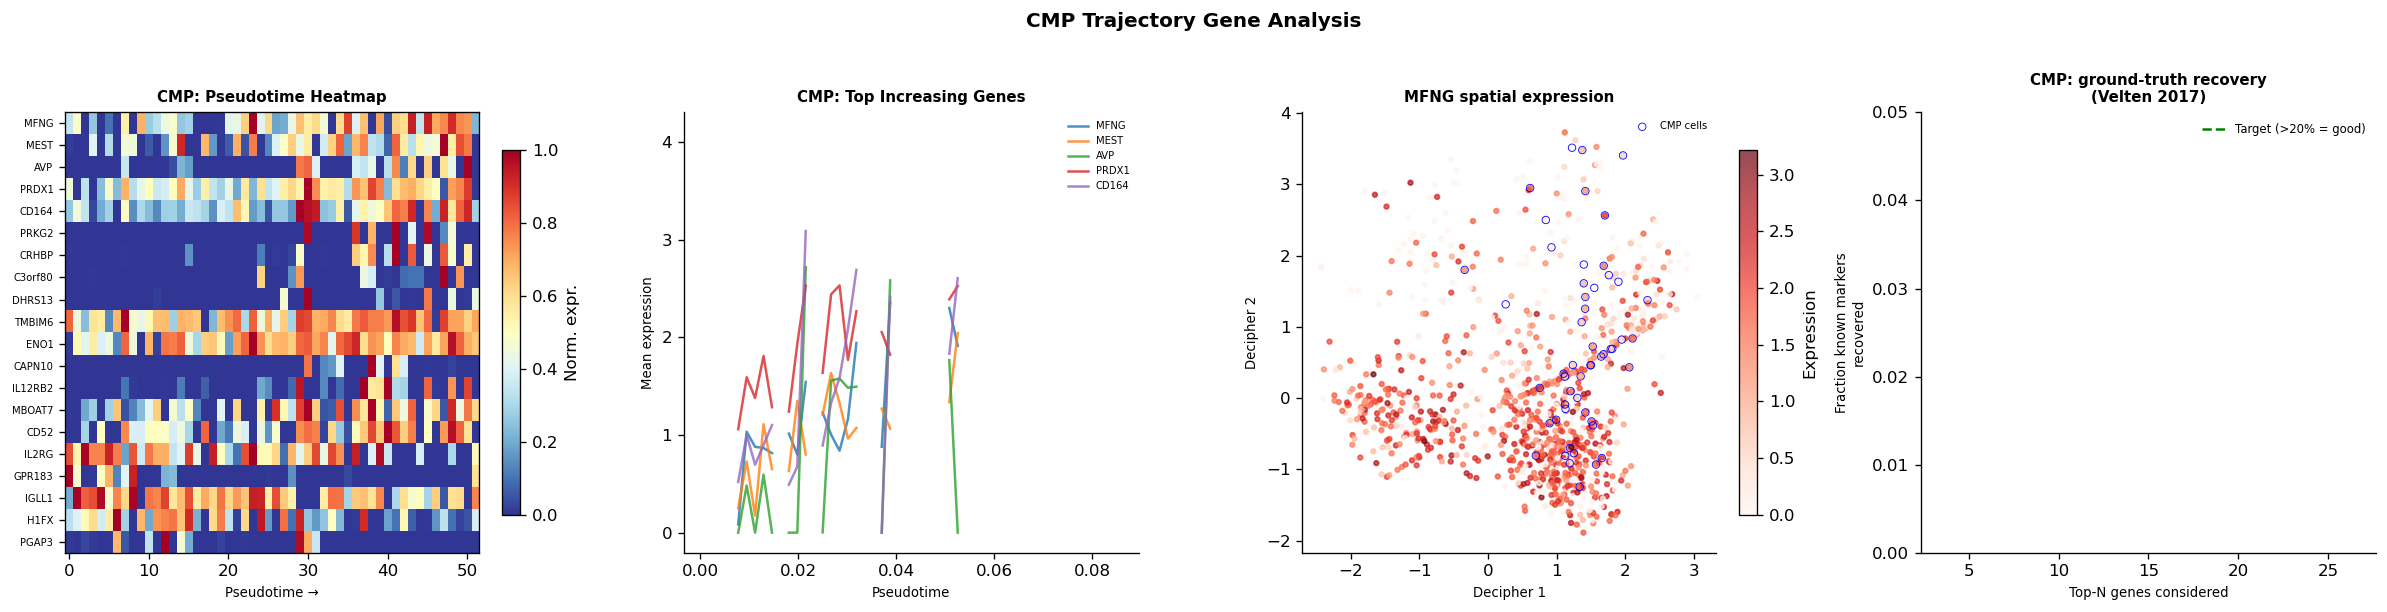


── GMP ─────────────────────────────────────────────
  Top genes INCREASING with pseudotime (should include lineage markers):
    P4HB             ρ=0.390  
    PRTN3            ρ=0.367  ✓ KNOWN MARKER
    ELANE            ρ=0.366  ✓ KNOWN MARKER
    CST7             ρ=0.327  ✓ KNOWN MARKER
    AZU1             ρ=0.320  ✓ KNOWN MARKER
    CTSG             ρ=0.296  
    MPO              ρ=0.257  ✓ KNOWN MARKER
    OSBPL5           ρ=0.257  
    KANSL3           ρ=0.253  
    SRGN             ρ=0.248  
  Top genes DECREASING (stem genes leaving):
    RBPMS            ρ=-0.280  
    GUCY1A3          ρ=-0.269  
    MS4A4A           ρ=-0.269  
    FLT3             ρ=-0.262  
    C9orf69          ρ=-0.258  
  ✓ Known markers recovered in top-10: [np.str_('PRTN3'), np.str_('ELANE'), np.str_('CST7'), np.str_('AZU1'), np.str_('MPO')]
  Ground-truth hit rate (top-25): 38.5%


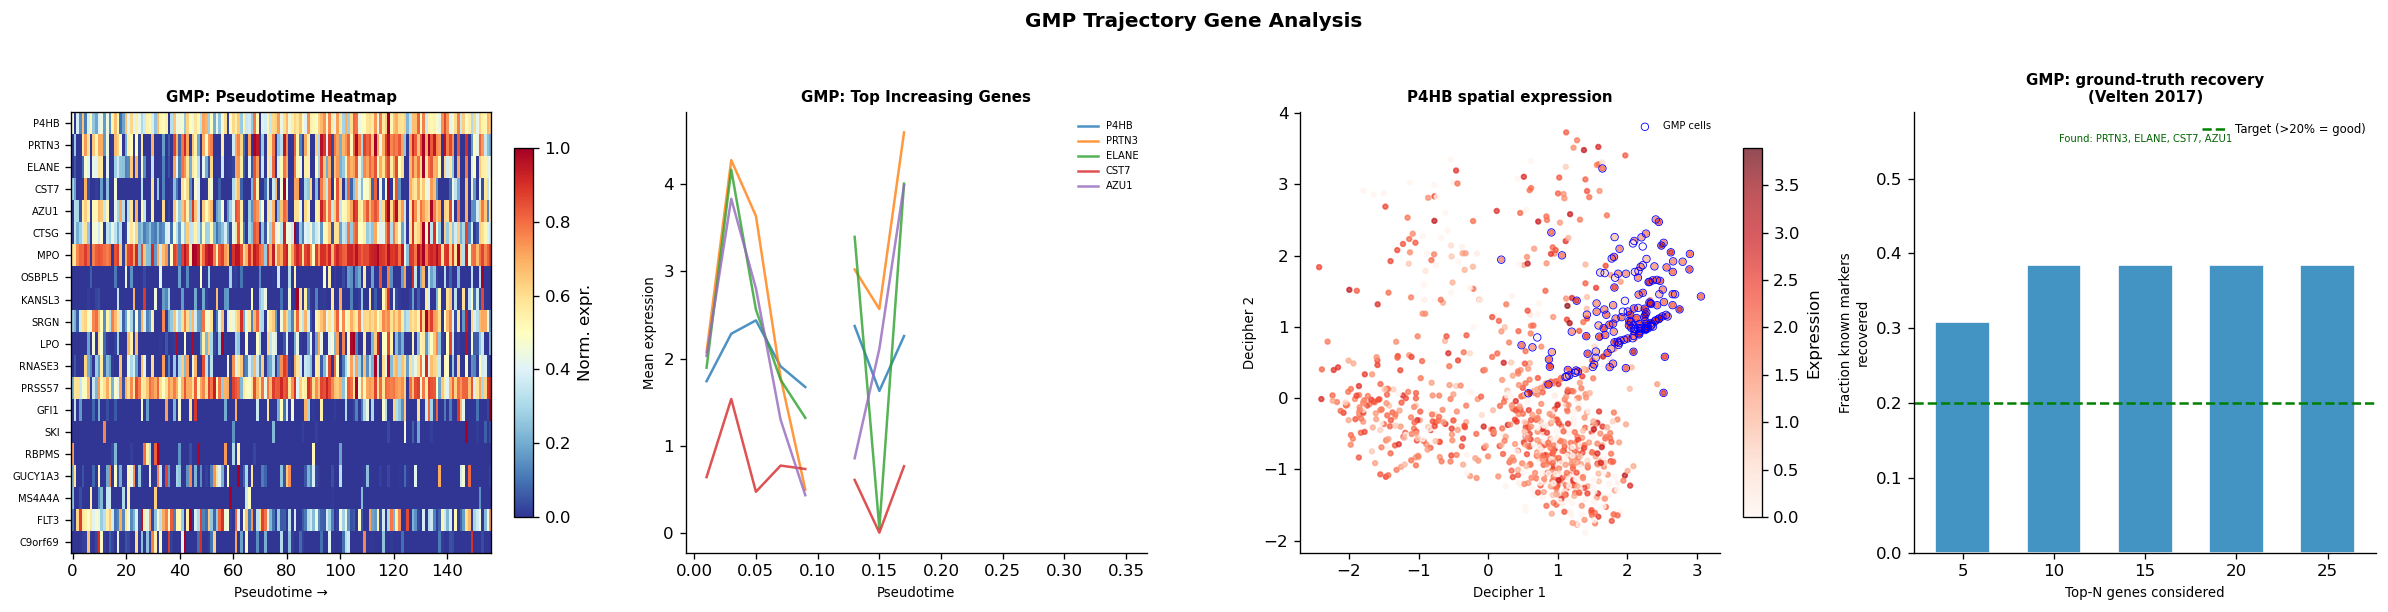


── HSC ─────────────────────────────────────────────
  Top genes INCREASING with pseudotime (should include lineage markers):
    PRSS23           ρ=0.377  
    FBLN1            ρ=0.368  
    TIMP3            ρ=0.362  
    C10orf10         ρ=0.349  
    TRIOBP           ρ=0.348  
    NAV2             ρ=0.347  
    HMG20B           ρ=0.344  
    MDK              ρ=0.341  
    CLEC3B           ρ=0.318  
    HECTD3           ρ=0.317  
  Top genes DECREASING (stem genes leaving):
    IGLL1            ρ=-0.399  
    PLAC8            ρ=-0.341  
    PRAM1            ρ=-0.340  
    ITGAL            ρ=-0.333  
    LAT2             ρ=-0.321  
  ✓ Known markers recovered in top-10: []
  Ground-truth hit rate (top-25): 0.0%


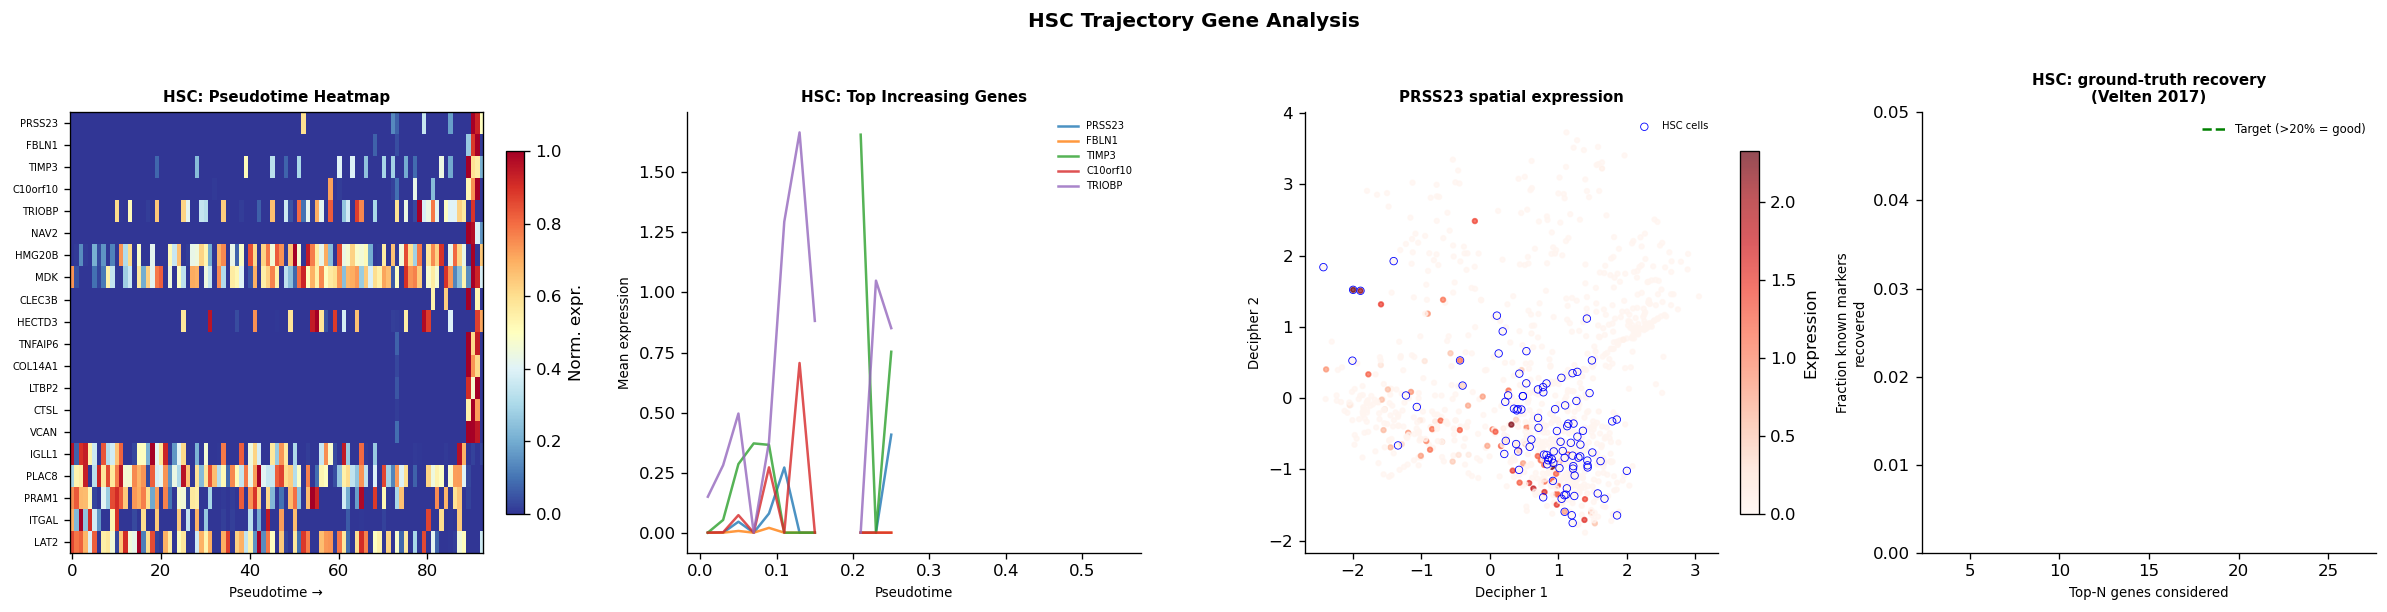


── MEP ─────────────────────────────────────────────
  Top genes INCREASING with pseudotime (should include lineage markers):
    PLEK             ρ=0.503  
    HEMGN            ρ=0.490  
    CD164            ρ=0.426  
    PKM              ρ=0.421  
    MPL              ρ=0.419  
    MDK              ρ=0.404  
    H2AFY            ρ=0.403  
    ZYX              ρ=0.400  
    TMSB4X           ρ=0.398  
    SERPINB6         ρ=0.398  
  Top genes DECREASING (stem genes leaving):
    CD36             ρ=-0.404  
    APOC1            ρ=-0.389  
    FBXO7            ρ=-0.374  
    PLIN2            ρ=-0.364  
    BLVRB            ρ=-0.363  
  ✓ Known markers recovered in top-10: []
  Ground-truth hit rate (top-25): 0.0%


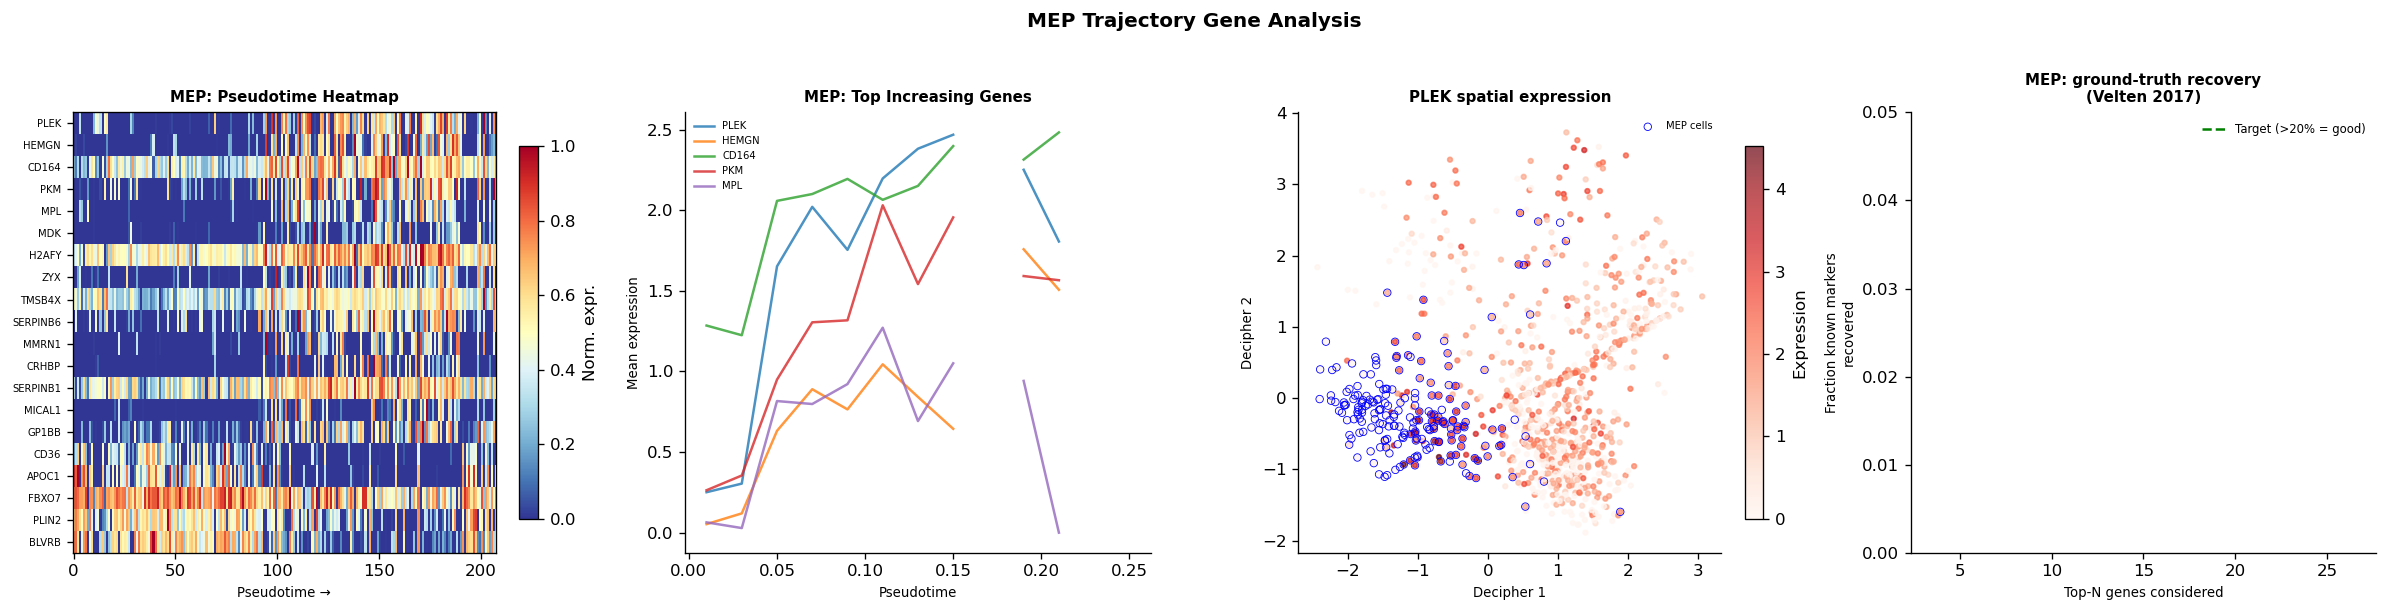


── MLP ─────────────────────────────────────────────
  Top genes INCREASING with pseudotime (should include lineage markers):
    MEST             ρ=0.554  
    NFE2             ρ=0.548  
    AVP              ρ=0.511  
    BCKDK            ρ=0.501  
    CSF3R            ρ=0.495  
    ENO1             ρ=0.493  
    PIGT             ρ=0.472  
    NPDC1            ρ=0.465  
    PROM1            ρ=0.442  
    CD34             ρ=0.442  
  Top genes DECREASING (stem genes leaving):
    BLNK             ρ=-0.700  
    ACTG1            ρ=-0.605  
    FAM129C          ρ=-0.544  
    TMSB4X           ρ=-0.515  
    RASD1            ρ=-0.503  
  ✓ Known markers recovered in top-10: []
  Ground-truth hit rate (top-25): 0.0%


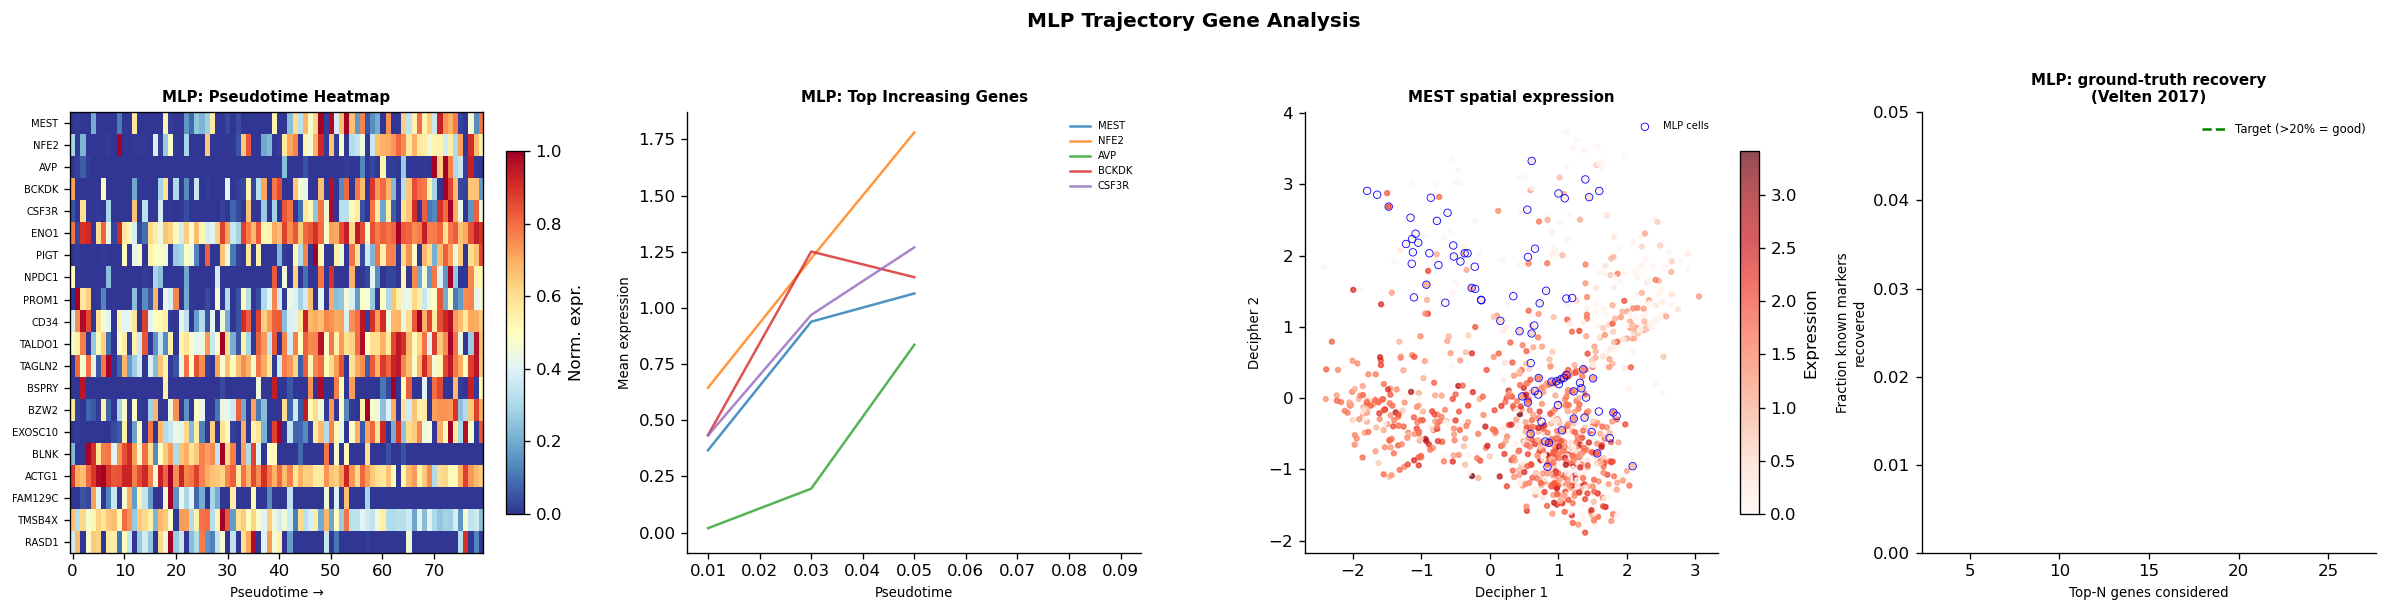


── MPP ─────────────────────────────────────────────
  Top genes INCREASING with pseudotime (should include lineage markers):
    FCER1A           ρ=0.443  
    SLC40A1          ρ=0.422  
    GP1BB            ρ=0.387  
    GATA2            ρ=0.352  ✓ KNOWN MARKER
    CLU              ρ=0.327  
    PTGS1            ρ=0.313  
    FTH1             ρ=0.271  
    TMEM246          ρ=0.270  
    CKB              ρ=0.269  
    RNF130           ρ=0.261  
  Top genes DECREASING (stem genes leaving):
    C1QTNF4          ρ=-0.384  
    IGLL1            ρ=-0.318  
    MZB1             ρ=-0.316  
    LAT2             ρ=-0.305  
    CD99             ρ=-0.299  
  ✓ Known markers recovered in top-10: [np.str_('GATA2')]
  Ground-truth hit rate (top-25): 25.0%


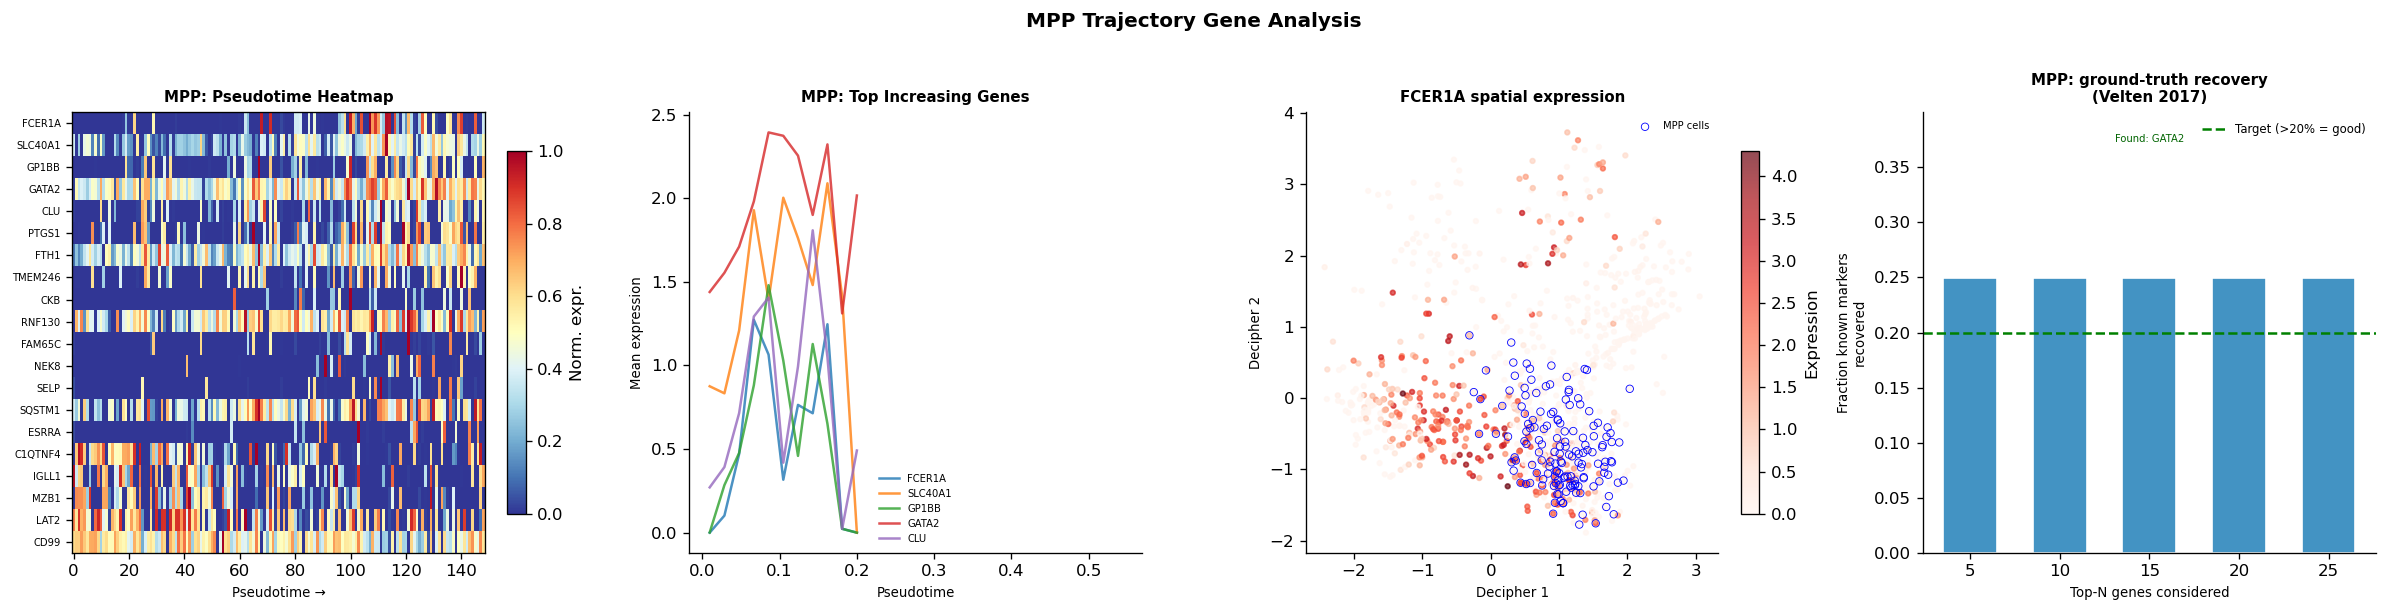


GROUND TRUTH SUMMARY (Velten 2017)
HSC → MEP:  GATA1, GATA2, KLF1, EPOR, GYPA, HBB, AHSP
HSC → GMP:  MPO, ELANE, SPI1, LYZ, CEBPA, PRTN3
HSC → MLP:  IL7R, DNTT, FLT3, RAG1, EBF1, CD79A
HSC stem (decreasing): CD34, HLF, HOXA9, GATA2, MEIS1

For each lineage, check the heatmap (Panel 1) and curves (Panel 2).
Known markers should appear near the TOP of the heatmap and show rising curves.
GRN SPARSITY REPORT
Matrix: 2820 genes × 277 TFs = 781,140 entries
Motif-supported edges: 257,277  (32.9%)
 |w| >  # edges % motif-supported % all possible
 0.001   254539             98.9%         32.59%
 0.005   243654             94.7%         31.19%
 0.010   225854             87.8%         28.91%
 0.050     1759              0.7%          0.23%

Per-TF active targets (|w|>0.01): median=755, mean=815.4
Shared: 1782 genes, 277 TFs
Global Spearman (nonzero support): ρ=0.2774
Per-TF Spearman: mean=0.8519 ± 0.1223, frac positive=1.000
Top 5% Jaccard: 0.1993
Top 10% Jaccard: 0.2966
Top 20% Jaccard: 0.5139

/home/sc5625/cll_project/decipher_atac_project/decipher-atac/comet/tools/grn_analysis.py:211: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top10, x='per_tf_spearman', y='tf', palette='viridis', ax=axes[1])


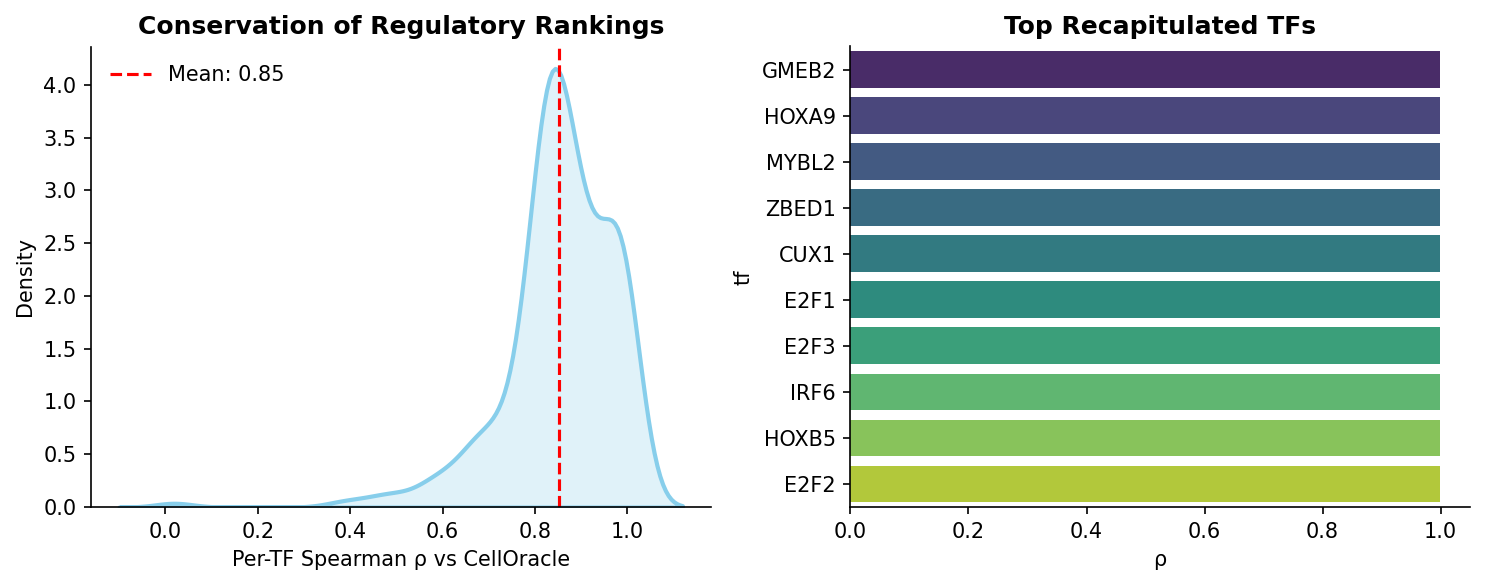

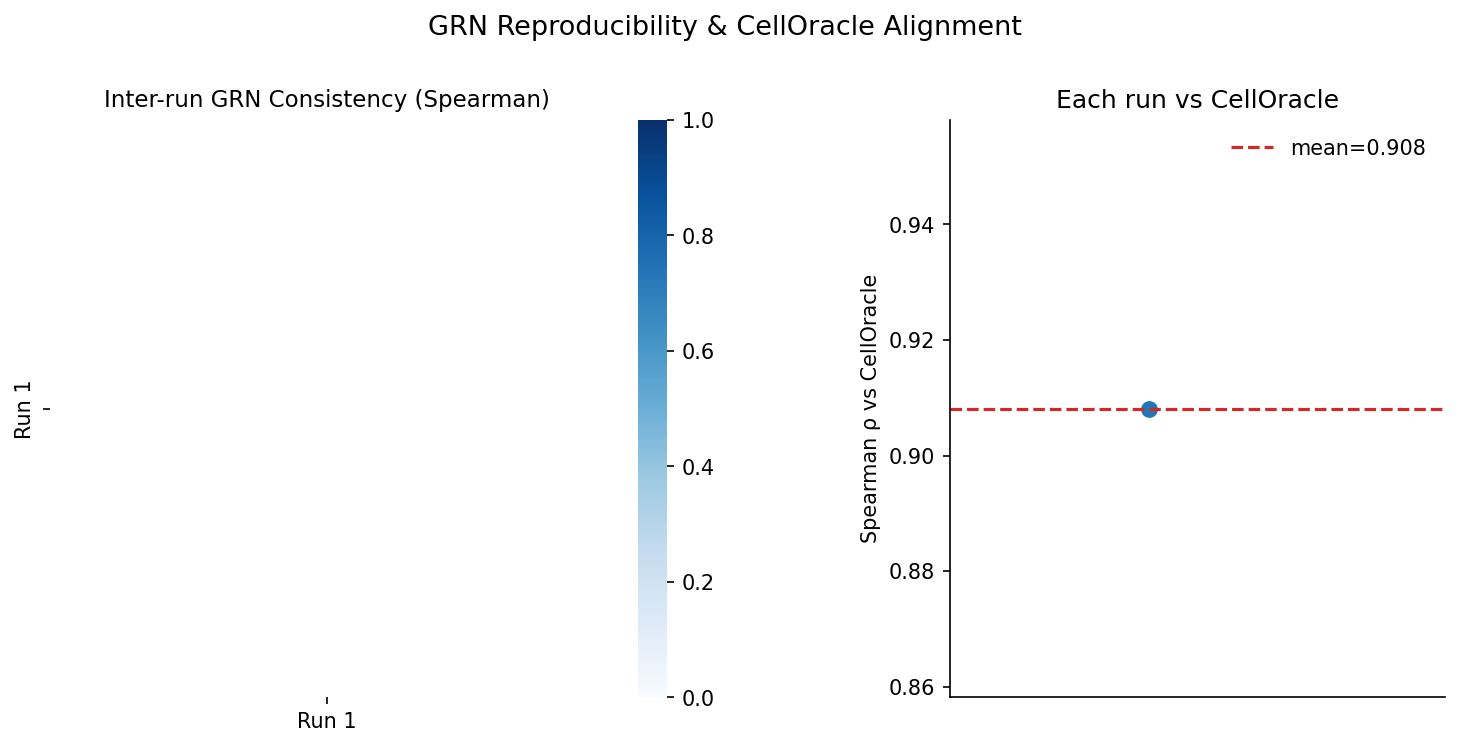

In [6]:
import os
import numpy as np

from config import CONFIG
from data.load import load_all_data
from model.velocity import project_to_2d
from model.ld_vae import plot_ld_embedding
from tools import (
    compute_comet_pseudotime, assign_velten_celltypes,
    plot_loss_curves, plot_atom_weights, plot_pseudotime,
    plot_velocity_streamlines, plot_marker_expression,
    analyze_transition_zones, analyze_trajectory_genes,
    grn_sparsity_report, compare_to_celloracle, plot_grn_consistency,
)

run    = f"{CONFIG['OUTPUT_DIR']}/run0"     # -> outputs/run0
plots  = f"{run}/plots"                     # all figures below land here
os.makedirs(plots, exist_ok=True)

data   = load_all_data(CONFIG)
X      = data["X"]
A_genes, A_tfs = data["A_genes"], data["A_tfs"]
rna_adata      = data["rna_adata"]

V_pred    = np.load(f"{run}/V_pred.npy")
V_dec2    = np.load(f"{run}/V_dec2.npy")
mix_w     = np.load(f"{run}/mix_weights.npy")
A_dict_np = np.load(f"{run}/A_dict.npy")        # (D, G, T)
z_ld_2d   = np.load(f"{run}/z_ld_2d.npy")
gene_loadings = np.load(f"{run}/gene_loadings.npy")

# ── 1. Training loss curves (3-panel Phase 1/2 convergence) ────────────────
import json
with open(f"{run}/loss_history.json") as f:
    loss_history = json.load(f)
# plot_loss_curves(loss_history, run_name="Run 0",
#                   save_path=f"{plots}/loss_curves.png")

# ── 2. LD-VAE biplot (RNA/ATAC embedding + gene-loading arrows) ────────────
pt_key = CONFIG["OBS_PSEUDOTIME_KEY"]
pseudo = rna_adata.obs[pt_key].astype(np.float32).values
pseudo_norm = (pseudo - pseudo.min()) / (pseudo.max() - pseudo.min() + 1e-8)
plot_ld_embedding(
    z_2d_rna=z_ld_2d, pseudo_norm=pseudo_norm,
    gene_loadings=gene_loadings, A_genes=A_genes,
    highlight_genes=CONFIG["LD_HIGHLIGHT_GENES"],
    save_path=f"{plots}/ld_embedding_biplot.png",
)

# ── 3. Per-atom GRN mixing-weight spatial plots ────────────────────────────
origin_atom = int(np.argmin(mix_w.mean(axis=0)))
plot_atom_weights(V_dec2, mix_w, CONFIG["D_ATOMS"], origin_atom,
                   A_tfs=A_tfs, A_dict_np=A_dict_np,
                   save_path=f"{plots}/atom_weights_spatial.png")

# ── 4. Cell-type assignment (Velten 2017 FACS gates) ───────────────────────
X_full = np.asarray(rna_adata.X.toarray() if hasattr(rna_adata.X, "toarray")
                     else rna_adata.X, dtype=np.float32)
gene_to_idx_full = {g: i for i, g in enumerate(rna_adata.var_names)}
cell_types = assign_velten_celltypes(rna_adata, V_dec2, X_full, gene_to_idx_full,
                                      save_path=f"{plots}/celltype_assignment.png")

# ── 5. Velocity pseudotime + streamlines ───────────────────────────────────
pt = compute_comet_pseudotime(V_pred, X, V_dec2, mix_w, cell_types=cell_types)
plot_pseudotime(V_dec2, pt, cell_types, facs_pseudotime=pseudo,
                 save_path=f"{plots}/pseudotime.png")

V_smooth = project_to_2d(V_pred, V_dec2, X, k=12, scale=12.0)
plot_velocity_streamlines(V_dec2, V_smooth, all_weights=mix_w,
                           cell_types=cell_types, facs_pseudotime=pseudo,
                           space_label="Decipher", base_path=plots)

# ── 6. Marker gene expression in Decipher space ────────────────────────────
plot_marker_expression(rna_adata, V_dec2,
                        save_path=f"{plots}/marker_expression.png")

# ── 7. Transition-zone analysis (GRN entropy vs. velocity magnitude) ───────
analyze_transition_zones(mix_w, V_smooth, V_dec2, CONFIG["D_ATOMS"],
                          save_path=f"{plots}/transition_zones.png")

# ── 8. Per-lineage trajectory genes (one figure per lineage) ───────────────
analyze_trajectory_genes(X, V_dec2, cell_types, A_genes, pt,
                          save_path=f"{plots}/trajectory_genes.png")

# ── 9. GRN sparsity report (printed, no figure) ────────────────────────────
A_learned = np.einsum('d,dgt->gt', mix_w.mean(axis=0), A_dict_np)  # consensus GRN
grn_sparsity_report(A_learned, A_genes, A_tfs, data["M"])

# ── 10. CellOracle comparison + inter-run GRN consistency ──────────────────
co_dir    = CONFIG["CELLORACLE_A_DIR"]     # data/cell_oracle_run/cell_oracle_global_A
co_A      = np.load(f"{co_dir}/A_celloracle.npy")
co_genes  = np.load(f"{co_dir}/A_genes.npy", allow_pickle=True)
co_tfs    = np.load(f"{co_dir}/A_tfs.npy", allow_pickle=True)
tf_df, A_co_shared, common_genes, common_tfs = compare_to_celloracle(
    A_learned, A_genes, A_tfs, co_A, co_genes, co_tfs,
    save_path=f"{plots}/celloracle_comparison.png",
)

# Needs NUM_RUNS > 1 in config.py (one outputs/run<i>/ per run already trained)
run_matrices = []
for i in range(CONFIG["NUM_RUNS"]):
    r  = f"{CONFIG['OUTPUT_DIR']}/run{i}"
    Ad = np.load(f"{r}/A_dict.npy")
    w  = np.load(f"{r}/mix_weights.npy")
    run_matrices.append((
        np.einsum('d,dgt->gt', w.mean(axis=0), Ad),
        np.load(f"{r}/A_genes.npy"), np.load(f"{r}/A_tfs.npy"),
    ))
plot_grn_consistency(run_matrices, A_co_shared, common_genes, common_tfs,
                      save_path=f"{plots}/grn_consistency.png")